# Execução no CoppeliaSim: trajetória, goals e camada reativa

Este notebook executa o experimento de navegação autônoma do Pioneer P3-DX no CoppeliaSim, integrando o planejamento global deliberativo (**Pessoa A**) com o sistema reativo dinâmico (**Pessoa B**).

**O que é exibido:**

- goals sorteados, numerados no referencial do mapa;
- rota global estática planejada para cada goal (linha tracejada via D* Lite);
- trajetória realmente percorrida pelo Pioneer no CoppeliaSim (linha contínua);
- goals efetivamente alcançados;
- rota, goals e rastro desenhados no viewport do CoppeliaSim;
- diagnóstico e telemetria da camada reativa dinâmica (Pessoa B): lookahead, atração, repulsão por campos potenciais, quebra de simetria à direita, células dinâmicas e recuperação de estagnação;
- última cena percebida pelo laser Hokuyo e mapa global acumulado de leituras.

Antes de executar: abra `cenas/MapaTP2.ttt` no CoppeliaSim, habilite o add-on **ZMQ Remote API** e deixe a simulação parada. O ambiente do kernel precisa ter `numpy`, `Pillow`, `matplotlib` e `coppeliasim_zmqremoteapi_client`.

In [1]:
from __future__ import annotations

import importlib
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from PIL import Image


def encontrar_raiz(inicio: Path) -> Path:
    """Encontra a raiz do TP2 mesmo se o notebook for aberto de uma subpasta."""
    for candidato in (inicio.resolve(), *inicio.resolve().parents):
        if (candidato / 'src' / 'Agente1.py').is_file() and (candidato / 'images' / 'tp2mapa.png').is_file():
            return candidato
    raise FileNotFoundError('Não foi possível encontrar src/Agente1.py e images/tp2mapa.png.')


RAIZ = encontrar_raiz(Path.cwd())
SRC = RAIZ / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# Recarrega os módulos locais ao reexecutar a célula no mesmo kernel do VS Code.
import Agente1 as agente_modulo
importlib.reload(agente_modulo)
from Agente1 import Agent, CamadaReativa, HokuyoSensorSim, PlanejadorGlobal, Sensoriamento


def gerar_goals_aleatorios_validos(planejador, pose_inicial, quantidade, *, seed=None, separacao_minima_m=1.0):
    """Sorteia goals livres, separados e alcancaveis no grid atual."""
    if quantidade < 0 or separacao_minima_m < 0:
        raise ValueError('quantidade e separacao_minima_m devem ser nao negativas')
    candidatas = [
        planejador.celula_para_mundo((linha, coluna))
        for linha, coluna in np.argwhere(~planejador.ocupacao)
    ]
    gerador = np.random.default_rng(seed)
    selecionadas = []
    for indice in gerador.permutation(len(candidatas)):
        candidata = candidatas[int(indice)]
        if math.dist(candidata, pose_inicial[:2]) < separacao_minima_m:
            continue
        if any(math.dist(candidata, outra) < separacao_minima_m for outra in selecionadas):
            continue
        planejador.definir_goal(candidata)
        if planejador.caminho_completo(pose_inicial):
            selecionadas.append(candidata)
        if len(selecionadas) == quantidade:
            return selecionadas
    raise ValueError('nao foi possivel gerar goals validos suficientes')

print(f'Raiz do projeto: {RAIZ}')
print(f'Módulo do agente recarregado: {agente_modulo.__file__}')


Raiz do projeto: /home/projval/Documents/dcc/robotica/tp2
Módulo do agente recarregado: /home/projval/Documents/dcc/robotica/tp2/src/Agente1.py


## Parâmetros do experimento

A mesma `SEED` reproduz a sequência de goals, desde que a pose inicial e o mapa sejam os mesmos. `AMOSTRA_A_CADA_PASSOS = 1` guarda cada pose; aumente-o se a execução for muito longa e você quiser menos pontos na trajetória.

In [2]:
SEED = 42
QUANTIDADE_GOALS = 5
SEPARACAO_MINIMA_M = 1.0
DURACAO_MAXIMA_S = 520.0
AMOSTRA_A_CADA_PASSOS = 1
PERIODO_LASER_S = 0.25
TOLERANCIA_RASTRO_M = 0.02
ALTURA_DESENHO_M = 0.04

if AMOSTRA_A_CADA_PASSOS < 1 or PERIODO_LASER_S <= 0:
    raise ValueError('A amostragem de poses e o periodo do laser devem ser positivos.')
if TOLERANCIA_RASTRO_M <= 0:
    raise ValueError('TOLERANCIA_RASTRO_M deve ser positiva.')

CAMINHO_MAPA = RAIZ / 'images' / 'tp2mapa.png'
imagem = np.asarray(Image.open(CAMINHO_MAPA).convert('RGB'))
agente = Agent(id_robo=1)
sensor = Sensoriamento()

escala = (
    agente.MAPA_LARGURA_M / imagem.shape[1],
    agente.MAPA_ALTURA_M / imagem.shape[0],
)
planejador_visual = PlanejadorGlobal(
    imagem,
    escala=escala,
    origem=agente.MAPA_ORIGEM,
    tamanho_celula_m=agente.TAMANHO_CELULA_M,
    raio_robo_m=agente.RAIO_ROBO_M,
    margem_seguranca_m=agente.MARGEM_SEGURANCA_M,
)

EXTENT = (
    agente.MAPA_ORIGEM[0],
    agente.MAPA_ORIGEM[0] + agente.MAPA_LARGURA_M,
    agente.MAPA_ORIGEM[1],
    agente.MAPA_ORIGEM[1] + agente.MAPA_ALTURA_M,
)
print(f'Mapa: {imagem.shape[1]} x {imagem.shape[0]} px; mundo: {EXTENT} m')
print(f'Camada reativa: lookahead={agente._camada_reativa.distancia_lookahead_m} m; raio_infl={agente._camada_reativa.raio_influencia_laser_m} m; saturação={agente._camada_reativa.distancia_saturacao_m} m; quebra_simetria={agente._camada_reativa.ganho_simetria}')


Mapa: 512 x 512 px; mundo: (-15.0, 15.0, -15.0, 15.0) m
Camada reativa: lookahead=0.6 m; raio_infl=0.9 m; saturação=0.32 m; quebra_simetria=0.3


## Função de visualização

A imagem é invertida verticalmente apenas na hora de desenhar. Isso faz o eixo `y` da figura crescer para cima, exatamente como o eixo mundial do CoppeliaSim; os dados do planejador não são alterados.

In [3]:
def plotar_execucao(
    *,
    goals: list[tuple[float, float]],
    pose_inicial: tuple[float, float, float],
    rotas_planejadas: list[list[tuple[float, float]]],
    trajetoria: list[tuple[float, float, float]] | None = None,
    quantidade_alcancada: int = 0,
):
    """Desenha mapa, goals, rotas globais e trajetória medida."""
    fig, ax = plt.subplots(figsize=(10, 10), constrained_layout=True)
    ax.imshow(np.flipud(imagem), extent=EXTENT, origin='lower', alpha=0.82)

    for indice, rota in enumerate(rotas_planejadas, start=1):
        if len(rota) < 2:
            continue
        pontos = np.asarray(rota)
        rotulo = 'rota global prevista' if indice == 1 else None
        ax.plot(pontos[:, 0], pontos[:, 1], '--', color='tab:orange', linewidth=1.4, alpha=0.8, label=rotulo)

    if trajetoria and len(trajetoria) > 1:
        pontos = np.asarray(trajetoria)
        ax.plot(pontos[:, 0], pontos[:, 1], '-', color='tab:blue', linewidth=2.2, label='trajetória medida')

    ax.scatter(pose_inicial[0], pose_inicial[1], s=95, marker='o', color='tab:purple', edgecolor='white', linewidth=1.0, zorder=5, label='pose inicial')
    for indice, (x, y) in enumerate(goals, start=1):
        alcancado = indice <= quantidade_alcancada
        cor = 'tab:green' if alcancado else 'tab:red'
        ax.scatter(x, y, s=95, marker='*', color=cor, edgecolor='white', linewidth=0.7, zorder=6)
        ax.annotate(f'G{indice}', (x, y), xytext=(6, 6), textcoords='offset points', color=cor, weight='bold')

    ax.set_xlim(EXTENT[0], EXTENT[1])
    ax.set_ylim(EXTENT[2], EXTENT[3])
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('x (m)')
    ax.set_ylabel('y (m)')
    ax.set_title('Mapa do CoppeliaSim — goals, rota global e trajetória')
    ax.grid(alpha=0.18)
    ax.legend(loc='upper right')
    return fig, ax

In [4]:
def matriz_coppelia_para_homogenea(matriz: list[float]) -> np.ndarray:
    """Converte a matriz 3x4 da API em matriz homogênea 4x4."""
    matriz_3x4 = np.asarray(matriz, dtype=float).reshape(3, 4)
    resultado = np.eye(4)
    resultado[:3, :4] = matriz_3x4
    return resultado


def transformar_pontos_laser_para_mundo(
    pontos_laser: np.ndarray,
    T_R_L: np.ndarray,
    T_W_R: np.ndarray,
) -> np.ndarray:
    """Aplica a cadeia ^W p = ^W T_R @ ^R T_L @ ^L p."""
    pontos = np.asarray(pontos_laser, dtype=float).reshape((-1, 3))
    if len(pontos) == 0:
        return np.empty((0, 2), dtype=float)
    pontos_homogeneos = np.column_stack((pontos, np.ones(len(pontos))))
    return (np.asarray(T_W_R) @ np.asarray(T_R_L) @ pontos_homogeneos.T).T[:, :2]


## Conectar, sortear goals e desenhar a rota na cena

Esta célula ainda não inicia a simulação. Ela lê a pose atual do robô, escolhe goals livres e alcançáveis, mostra o plano no notebook e desenha goals e rotas no viewport do CoppeliaSim. Os desenhos persistem quando a simulação é pausada; reexecutar esta célula remove os desenhos anteriores.

Pose inicial: (-0.32, -0.62, 1.57 rad)
G1: (-13.15, 11.95) m; 6 waypoints
G2: (-13.35, -11.85) m; 6 waypoints
G3: (-0.35, 7.65) m; 6 waypoints
G4: (-3.55, 5.55) m; 2 waypoints
G5: (-11.35, 4.05) m; 5 waypoints


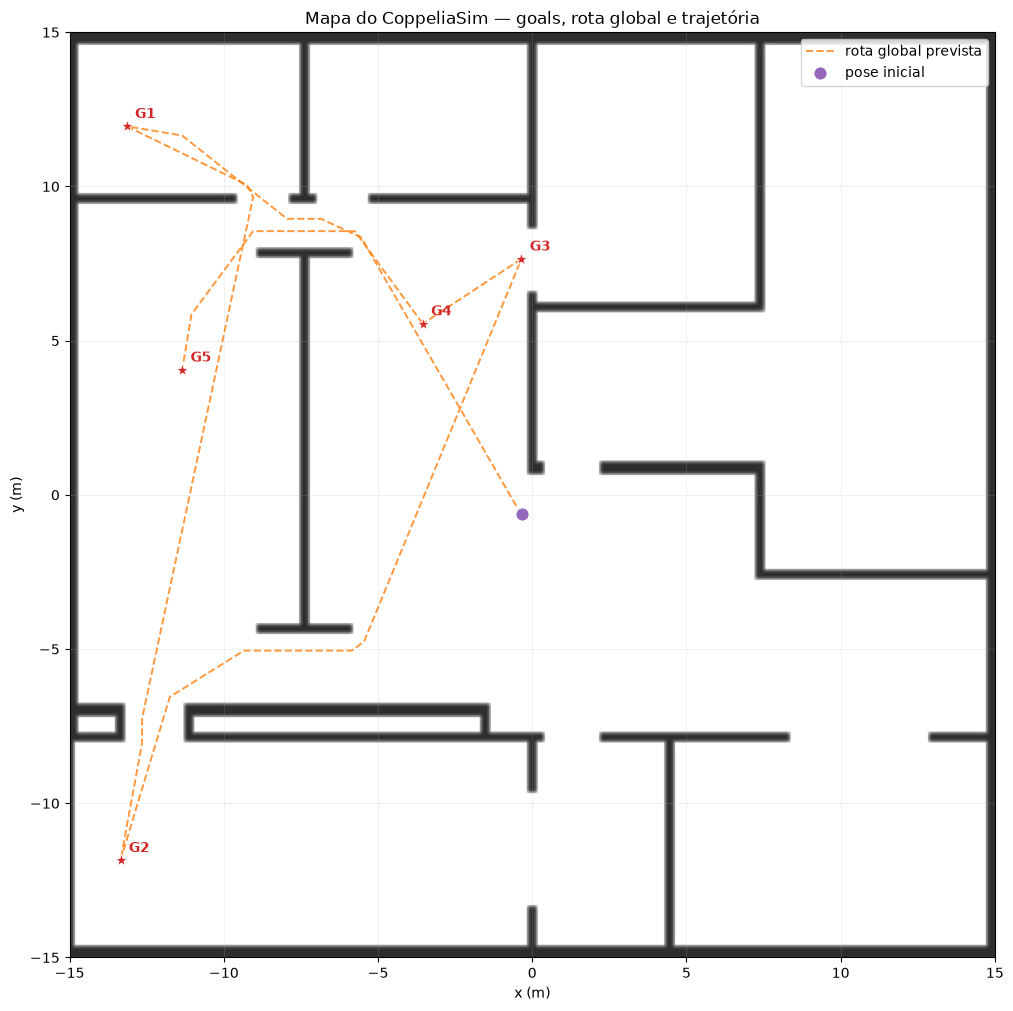

In [5]:
from coppeliasim_zmqremoteapi_client import RemoteAPIClient

cliente = RemoteAPIClient()
sim = cliente.require('sim')
cliente.setStepping(True)

pose_inicial = sensor.obter_pose(sim, agente.robotname)
caminho_robo = '/' + agente.robotname
handle_robo = sim.getObject(caminho_robo)
handle_laser = sim.getObject(f'{caminho_robo}/fastHokuyo')
leitor_laser_global = HokuyoSensorSim(
    sim, f'{caminho_robo}/fastHokuyo', is_range_data=False
)
goals = gerar_goals_aleatorios_validos(
    planejador_visual,
    pose_inicial,
    QUANTIDADE_GOALS,
    seed=SEED,
    separacao_minima_m=SEPARACAO_MINIMA_M,
)

# Cada rota começa onde a anterior termina. Elas representam o plano estático,
# enquanto a trajetória real será medida durante a execução abaixo.
rotas_planejadas: list[list[tuple[float, float]]] = []
origem_rota = (pose_inicial[0], pose_inicial[1], pose_inicial[2])
for goal in goals:
    planejador_visual.definir_goal(goal)
    rota = planejador_visual.caminho_completo(origem_rota)
    if not rota:
        raise RuntimeError(f'Não há rota global para o goal {goal}.')
    rotas_planejadas.append(rota)
    origem_rota = (goal[0], goal[1], 0.0)

# Desenhos persistentes no viewport do CoppeliaSim.
for handle in globals().get('DESENHOS_CENA', []):
    try:
        sim.removeDrawingObject(handle)
    except Exception:
        pass

rota_handle = sim.addDrawingObject(
    sim.drawing_lines | sim.drawing_persistent,
    3.0, 0.0, -1, 30_000, [1.0, 0.55, 0.0],
)
rastro_handle = sim.addDrawingObject(
    sim.drawing_lines | sim.drawing_persistent,
    4.0, 0.0, -1, 30_000, [0.0, 0.45, 1.0],
)
goals_handle = sim.addDrawingObject(
    sim.drawing_spherepoints | sim.drawing_persistent,
    0.18, 0.0, -1, len(goals), [1.0, 0.0, 0.0],
)
goals_alcancados_handle = sim.addDrawingObject(
    sim.drawing_spherepoints | sim.drawing_persistent,
    0.24, 0.0, -1, len(goals), [0.0, 1.0, 0.0],
)
DESENHOS_CENA = [rota_handle, rastro_handle, goals_handle, goals_alcancados_handle]

for rota in rotas_planejadas:
    for inicio, fim in zip(rota, rota[1:]):
        sim.addDrawingObjectItem(
            rota_handle,
            [inicio[0], inicio[1], ALTURA_DESENHO_M, fim[0], fim[1], ALTURA_DESENHO_M],
        )
for x, y in goals:
    sim.addDrawingObjectItem(goals_handle, [x, y, ALTURA_DESENHO_M])

print(f'Pose inicial: ({pose_inicial[0]:.2f}, {pose_inicial[1]:.2f}, {pose_inicial[2]:.2f} rad)')
for indice, goal in enumerate(goals, start=1):
    print(f'G{indice}: ({goal[0]:.2f}, {goal[1]:.2f}) m; {len(rotas_planejadas[indice - 1])} waypoints')
plotar_execucao(
    goals=goals,
    pose_inicial=pose_inicial,
    rotas_planejadas=rotas_planejadas,
)
plt.show()

## Executar e registrar a trajetória

A célula é equivalente ao laço do script original, com uma diferença: antes de cada passo ela armazena a pose `(x, y, θ)` do robô. O bloco `finally` para a simulação mesmo em caso de erro. Execute esta célula uma vez por experimento.

In [6]:
trajetoria: list[tuple[float, float, float]] = [pose_inicial]
pontos_laser_mundo: list[list[float]] = []
historico_celulas_bloqueadas: list[int] = [0]
passos_recuperacao_total = 0
historico_tempos: list[float] = [0.0]
ultimo_laser_local: np.ndarray = np.empty((0, 2))
quantidade_alcancada = 0
passos = 0
tempo_final_s = 0.0
simulacao_iniciada = False
ultima_pose_desenhada = pose_inicial
ultimo_tempo_laser = -math.inf


def registrar_varredura_global() -> int:
    """Converte uma varredura Hokuyo para o mundo e a acumula no mapa."""
    pontos_laser = leitor_laser_global.getSensorData()
    if len(pontos_laser) == 0:
        return 0
    distancias = np.linalg.norm(pontos_laser[:, :2], axis=1)
    pontos_laser = pontos_laser[np.isfinite(distancias) & (distancias > 0.0) & (distancias < 4.9)]
    if len(pontos_laser) == 0:
        return 0
    T_R_L = matriz_coppelia_para_homogenea(sim.getObjectMatrix(handle_laser, handle_robo))
    T_W_R = matriz_coppelia_para_homogenea(sim.getObjectMatrix(handle_robo, sim.handle_world))
    pontos_novos = transformar_pontos_laser_para_mundo(pontos_laser, T_R_L, T_W_R)
    pontos_laser_mundo.extend(pontos_novos.tolist())
    return len(pontos_novos)


try:
    sim.startSimulation()
    simulacao_iniciada = True

    while sim.getSimulationTime() < DURACAO_MAXIMA_S:
        pose_atual = sensor.obter_pose(sim, agente.robotname)
        if passos % AMOSTRA_A_CADA_PASSOS == 0:
            trajetoria.append(pose_atual)
            historico_tempos.append(float(sim.getSimulationTime()))
            historico_celulas_bloqueadas.append(len(agente._camada_reativa._celulas_bloqueadas))
            if agente._camada_reativa._estado_recuperacao != CamadaReativa.ESTADO_NORMAL:
                passos_recuperacao_total += 1
        tempo_atual = float(sim.getSimulationTime())
        if tempo_atual - ultimo_tempo_laser >= PERIODO_LASER_S:
            registrar_varredura_global()
            ultimo_tempo_laser = tempo_atual

        if math.dist(ultima_pose_desenhada[:2], pose_atual[:2]) >= TOLERANCIA_RASTRO_M:
            sim.addDrawingObjectItem(
                rastro_handle,
                [
                    ultima_pose_desenhada[0], ultima_pose_desenhada[1], ALTURA_DESENHO_M,
                    pose_atual[0], pose_atual[1], ALTURA_DESENHO_M,
                ],
            )
            ultima_pose_desenhada = pose_atual

        if agente.movement(sim, imagem, goals):
            goal_alcancado = goals[quantidade_alcancada]
            sim.addDrawingObjectItem(
                goals_alcancados_handle,
                [goal_alcancado[0], goal_alcancado[1], ALTURA_DESENHO_M],
            )
            quantidade_alcancada += 1
            print(f'Goal {quantidade_alcancada}/{len(goals)} alcançado em t={sim.getSimulationTime():.2f} s')
            if quantidade_alcancada == len(goals):
                break

        cliente.step()
        passos += 1

    pose_final = sensor.obter_pose(sim, agente.robotname)
    ultimo_laser_local = sensor.obter_laser(sim, agente.robotname)
    registrar_varredura_global()
    if trajetoria[-1] != pose_final:
        trajetoria.append(pose_final)
    if math.dist(ultima_pose_desenhada[:2], pose_final[:2]) >= 1e-9:
        sim.addDrawingObjectItem(
            rastro_handle,
            [
                ultima_pose_desenhada[0], ultima_pose_desenhada[1], ALTURA_DESENHO_M,
                pose_final[0], pose_final[1], ALTURA_DESENHO_M,
            ],
        )
    tempo_final_s = float(sim.getSimulationTime())
finally:
    if simulacao_iniciada:
        sim.stopSimulation()

print(
    f'Resultado: {quantidade_alcancada}/{len(goals)} goals em {tempo_final_s:.2f} s; '
    f'{len(trajetoria)} poses e {len(pontos_laser_mundo)} pontos de laser no mundo registrados; '
    f'Camada reativa: {passos_recuperacao_total} passos em recuperação de estagnação; '
    f'máximo de {max(historico_celulas_bloqueadas, default=0)} células dinâmicas bloqueadas simultaneamente.'
)


Goal 1/5 alcançado em t=61.95 s
Goal 2/5 alcançado em t=119.60 s
Goal 3/5 alcançado em t=173.95 s
Goal 4/5 alcançado em t=183.00 s
Goal 5/5 alcançado em t=239.80 s
Resultado: 5/5 goals em 239.80 s; 4798 poses e 378146 pontos de laser no mundo registrados; Camada reativa: 198 passos em recuperação de estagnação; máximo de 7 células dinâmicas bloqueadas simultaneamente.


## Resultado visual e leitura

Azul é o caminho medido no simulador; laranja tracejado é o plano global sobre o mapa estático. Goals verdes foram alcançados e vermelhos ficaram pendentes. Uma diferença entre azul e laranja não prova falha por si só: ela pode resultar da discretização do grid, do controle cinemático ou de obstáculos dinâmicos, que não entram nesse plano estático.

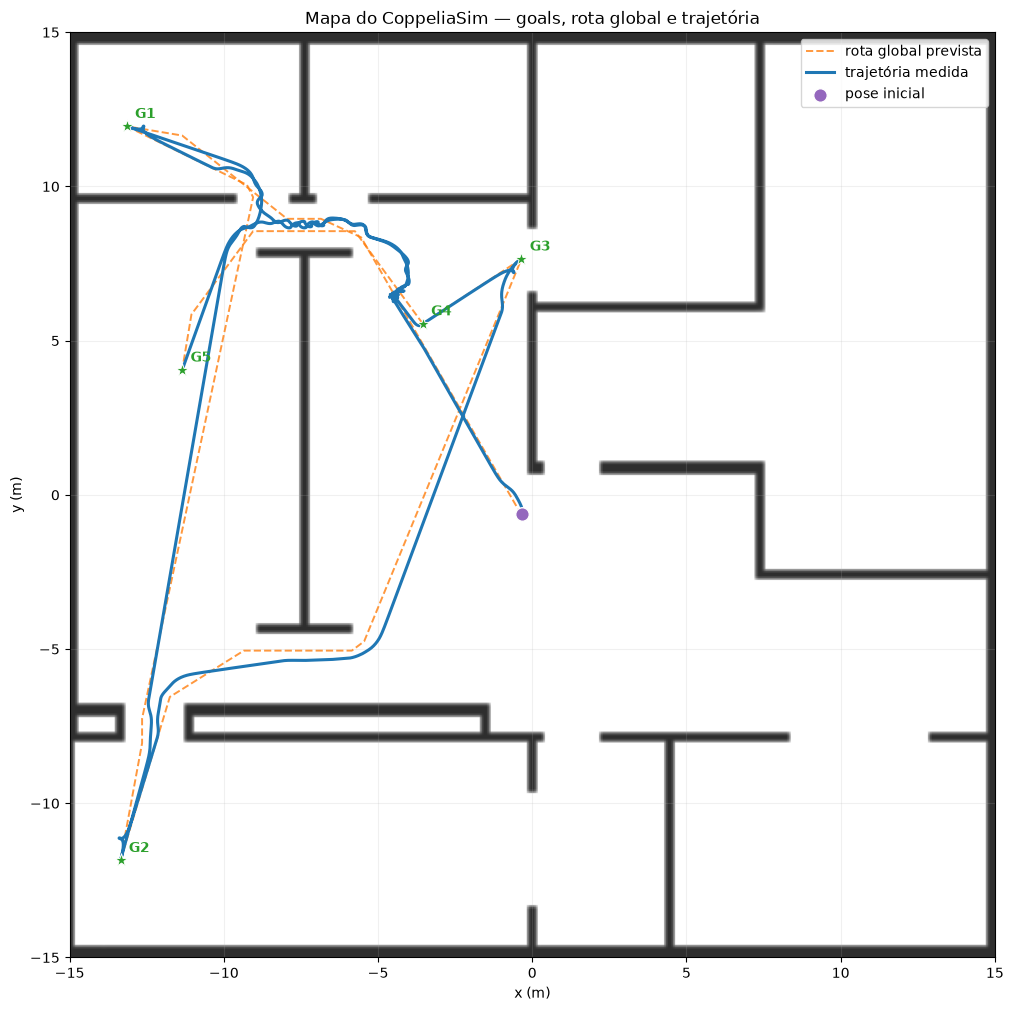

{'seed': 42,
 'tempo_simulado_s': 239.8,
 'goals_alcancados': '5/5',
 'poses_registradas': 4798,
 'distancia_percorrida_m': 98.58,
 'max_celulas_dinamicas_bloqueadas': 7,
 'passos_recuperacao_estagnacao': 198,
 'estado_recuperacao_final': 0}

**Leitura desta execução.** O robô percorreu aproximadamente **98.58 m** em **239.80 s** e alcançou **5/5** goals; todos os goals foram alcançados. A figura compara a trajetória observada com o plano estático, mas não mede colisões nem substitui a inspeção visual no CoppeliaSim.

In [7]:
fig, ax = plotar_execucao(
    goals=goals,
    pose_inicial=pose_inicial,
    rotas_planejadas=rotas_planejadas,
    trajetoria=trajetoria,
    quantidade_alcancada=quantidade_alcancada,
)
plt.show()

pontos_xy = np.asarray([(x, y) for x, y, _ in trajetoria])
distancia_percorrida_m = float(np.linalg.norm(np.diff(pontos_xy, axis=0), axis=1).sum()) if len(pontos_xy) > 1 else 0.0
if quantidade_alcancada < len(goals):
    goal_atual = goals[quantidade_alcancada]
    erro_goal_pendente_m = math.dist(pontos_xy[-1], goal_atual)
    leitura_goal = f'erro até G{quantidade_alcancada + 1}: {erro_goal_pendente_m:.2f} m'
else:
    leitura_goal = 'todos os goals foram alcançados'

metricas = {
    'seed': SEED,
    'tempo_simulado_s': round(tempo_final_s, 2),
    'goals_alcancados': f'{quantidade_alcancada}/{len(goals)}',
    'poses_registradas': len(trajetoria),
    'distancia_percorrida_m': round(distancia_percorrida_m, 2),
    'max_celulas_dinamicas_bloqueadas': max(historico_celulas_bloqueadas, default=0),
    'passos_recuperacao_estagnacao': passos_recuperacao_total,
    'estado_recuperacao_final': agente._camada_reativa._estado_recuperacao,
}
display(metricas)
display(Markdown(
    f'**Leitura desta execução.** O robô percorreu aproximadamente **{distancia_percorrida_m:.2f} m** '
    f'em **{tempo_final_s:.2f} s** e alcançou **{quantidade_alcancada}/{len(goals)}** goals; {leitura_goal}. '
    'A figura compara a trajetória observada com o plano estático, mas não mede colisões nem substitui a inspeção visual no CoppeliaSim.'
))


## Diagnóstico da Camada Reativa Dinâmica (Pessoa B)

Esta seção inspeciona o comportamento da camada reativa:

1. **Decomposição Vetorial Local:** projeta a varredura do laser Hokuyo no referencial do robô ($ à frente, $ à esquerda), ilustrando os limites de saturação e influência de repulsão, o cone frontal de quebra de simetria e os vetores de atração $\vec{v}_{att}$ (lookahead), repulsão $\vec{F}_{rep}$, quebra de simetria $\vec{F}_{sym}$ e a resultante $\vec{v}_{desejado}$ enviada ao controlador diferencial de Desai et al.
2. **Telemetria de Obstáculos Dinâmicos:** exibe o número de células dinâmicas temporariamente bloqueadas no grid D* Lite por persistência ao longo da missão.


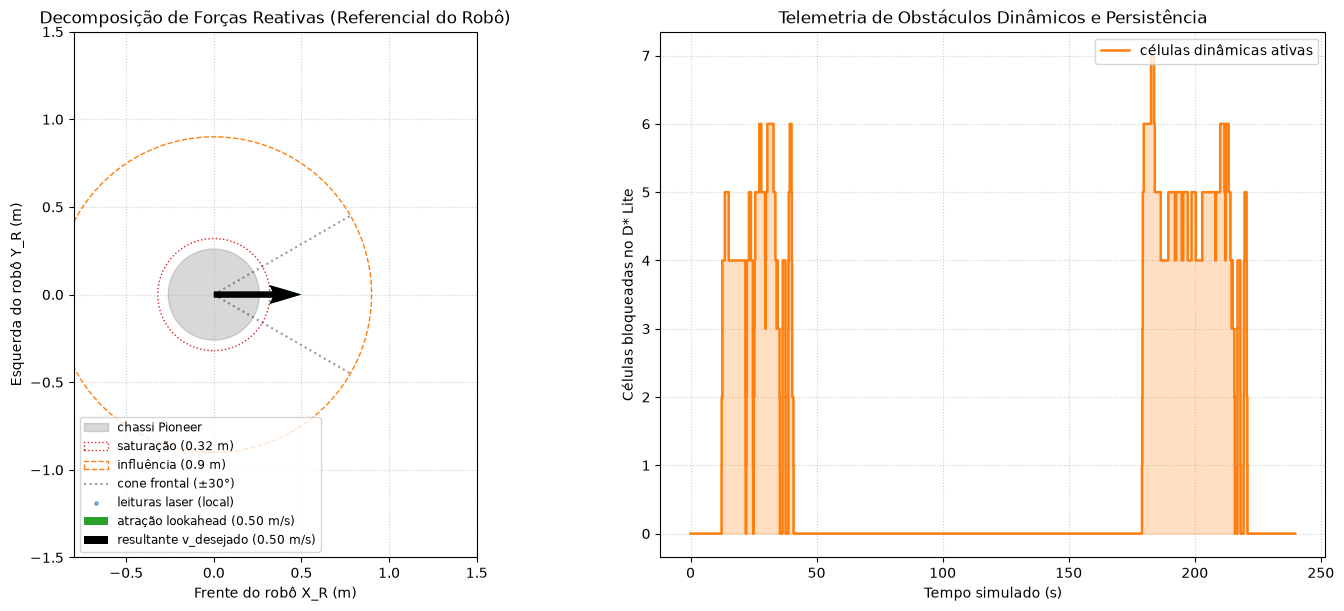

**Análise da camada reativa (Pessoa B):** O gráfico da esquerda demonstra a combinação instantânea entre a atração ao lookahead (verde), o campo potencial repulsivo do laser (vermelho) e a quebra de simetria à direita (roxo), produzindo o vetor resultante seguro (preto) fornecido ao controlador. O gráfico da direita registra a dinâmica de persistência e expiração das células dinâmicas sobre o grid D* Lite.

In [8]:
def plotar_diagnostico_camada_reativa(
    agente: Agent,
    pose: tuple[float, float, float],
    laser: np.ndarray,
    caminho: list[tuple[float, float]],
    goal: tuple[float, float],
    historico_tempos: list[float],
    historico_bloqueios: list[int],
):
    """Visualiza as forças reativas locais e a telemetria de bloqueios dinâmicos."""
    fig, (ax_vetores, ax_telemetria) = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

    cr = agente._camada_reativa
    xr, yr, theta = pose
    cos_th, sin_th = math.cos(theta), math.sin(theta)

    # 1. Desenha o chassi do robô e raios de saturação/influência
    circ_robo = plt.Circle((0, 0), agente.RAIO_ROBO_M, color="tab:gray", alpha=0.3, label="chassi Pioneer")
    circ_sat = plt.Circle((0, 0), cr.distancia_saturacao_m, fill=False, edgecolor="tab:red", linestyle=":", label=f"saturação ({cr.distancia_saturacao_m} m)")
    circ_inf = plt.Circle((0, 0), cr.raio_influencia_laser_m, fill=False, edgecolor="tab:orange", linestyle="--", label=f"influência ({cr.raio_influencia_laser_m} m)")
    ax_vetores.add_patch(circ_robo)
    ax_vetores.add_patch(circ_sat)
    ax_vetores.add_patch(circ_inf)

    # 2. Setor frontal de quebra de simetria (±30°)
    ang_f = cr.angulo_frontal_rad
    ax_vetores.plot([0, cr.raio_influencia_laser_m * math.cos(ang_f)], [0, cr.raio_influencia_laser_m * math.sin(ang_f)], "k:", alpha=0.4)
    ax_vetores.plot([0, cr.raio_influencia_laser_m * math.cos(-ang_f)], [0, cr.raio_influencia_laser_m * math.sin(-ang_f)], "k:", alpha=0.4, label="cone frontal (±30°)")

    # 3. Obstáculos detectados pelo laser no referencial do robô
    if laser is not None and len(laser) > 0:
        angulos = laser[:, 0]
        distancias = laser[:, 1]
        validos = np.isfinite(distancias) & (distancias > 0.02) & (distancias <= 4.9)
        px_local = distancias[validos] * np.cos(angulos[validos])
        py_local = distancias[validos] * np.sin(angulos[validos])
        ax_vetores.scatter(px_local, py_local, s=6, color="tab:blue", alpha=0.5, label="leituras laser (local)")

    # 4. Forças reativas em coordenadas locais do robô
    wp = cr.selecionar_lookahead(pose, caminho)
    v_att_w = cr.calcular_atracao(pose, wp) if wp is not None else (0.0, 0.0)
    f_rep_w = cr.calcular_repulsao(pose, laser)
    f_sym_w = cr.calcular_quebra_simetria(pose, laser)
    v_tot_w = cr.calcular_vetor_desejado(pose, caminho, laser, goal) or (0.0, 0.0)

    def mundo_para_local(vx_w: float, vy_w: float) -> tuple[float, float]:
        """Rotaciona vetor do mundo para o referencial do chassi."""
        return cos_th * vx_w + sin_th * vy_w, -sin_th * vx_w + cos_th * vy_w

    vx_att_l, vy_att_l = mundo_para_local(*v_att_w)
    fx_rep_l, fy_rep_l = mundo_para_local(*f_rep_w)
    fx_sym_l, fy_sym_l = mundo_para_local(*f_sym_w)
    vx_tot_l, vy_tot_l = mundo_para_local(*v_tot_w)

    ax_vetores.quiver(0, 0, vx_att_l, vy_att_l, angles="xy", scale_units="xy", scale=1, color="tab:green", width=0.012, zorder=6, label=f"atração lookahead ({math.hypot(vx_att_l, vy_att_l):.2f} m/s)")
    if math.hypot(fx_rep_l, fy_rep_l) > 1e-4:
        ax_vetores.quiver(0, 0, fx_rep_l, fy_rep_l, angles="xy", scale_units="xy", scale=1, color="tab:red", width=0.012, zorder=6, label=f"repulsão laser ({math.hypot(fx_rep_l, fy_rep_l):.2f} m/s)")
    if math.hypot(fx_sym_l, fy_sym_l) > 1e-4:
        ax_vetores.quiver(0, 0, fx_sym_l, fy_sym_l, angles="xy", scale_units="xy", scale=1, color="tab:purple", width=0.012, zorder=6, label="quebra simetria (direita)")
    ax_vetores.quiver(0, 0, vx_tot_l, vy_tot_l, angles="xy", scale_units="xy", scale=1, color="black", width=0.016, zorder=7, label=f"resultante v_desejado ({math.hypot(vx_tot_l, vy_tot_l):.2f} m/s)")

    lim_vis = max(1.5, cr.raio_influencia_laser_m + 0.3)
    ax_vetores.set_xlim(-0.8, lim_vis)
    ax_vetores.set_ylim(-lim_vis, lim_vis)
    ax_vetores.set_aspect("equal", adjustable="box")
    ax_vetores.set_xlabel("Frente do robô X_R (m)")
    ax_vetores.set_ylabel("Esquerda do robô Y_R (m)")
    ax_vetores.set_title("Decomposição de Forças Reativas (Referencial do Robô)")
    ax_vetores.grid(True, linestyle=":", alpha=0.6)
    ax_vetores.legend(loc="lower left", fontsize=8.5)

    # Painel 2: Telemetria temporal de células dinâmicas
    if len(historico_tempos) > 1 and len(historico_bloqueios) > 1:
        n_pts = min(len(historico_tempos), len(historico_bloqueios))
        ax_telemetria.step(historico_tempos[:n_pts], historico_bloqueios[:n_pts], where="post", color="tab:orange", linewidth=1.8, label="células dinâmicas ativas")
        ax_telemetria.fill_between(historico_tempos[:n_pts], historico_bloqueios[:n_pts], step="post", alpha=0.25, color="tab:orange")
    ax_telemetria.set_xlabel("Tempo simulado (s)")
    ax_telemetria.set_ylabel("Células bloqueadas no D* Lite")
    ax_telemetria.set_title("Telemetria de Obstáculos Dinâmicos e Persistência")
    ax_telemetria.grid(True, linestyle=":", alpha=0.6)
    ax_telemetria.legend(loc="upper right")

    return fig, (ax_vetores, ax_telemetria)


caminho_final = agente._planejador.caminho_completo(trajetoria[-1]) if agente._planejador is not None else []
fig_reativo, _ = plotar_diagnostico_camada_reativa(
    agente=agente,
    pose=trajetoria[-1],
    laser=ultimo_laser_local,
    caminho=caminho_final,
    goal=goals[min(quantidade_alcancada, len(goals) - 1)],
    historico_tempos=historico_tempos,
    historico_bloqueios=historico_celulas_bloqueadas,
)
plt.show()

display(Markdown(
    "**Análise da camada reativa (Pessoa B):** O gráfico da esquerda demonstra a combinação instantânea "
    "entre a atração ao lookahead (verde), o campo potencial repulsivo do laser (vermelho) e a quebra "
    "de simetria à direita (roxo), produzindo o vetor resultante seguro (preto) fornecido ao controlador. "
    "O gráfico da direita registra a dinâmica de persistência e expiração das células dinâmicas sobre o grid D* Lite."
))


## Mapa global percebido pelo Hokuyo

Cada varredura é lida no referencial local do laser e transformada pela cadeia
`^W p = ^W T_R · ^R T_L · ^L p`, como na Questão 5 do TP1. O gráfico acumula
os retornos válidos no mundo e os compara à trajetória realmente percorrida e
aos goals. Ele representa apenas o que foi detectado pelo Hokuyo; não é a
ocupação estática completa usada pelo planejador.


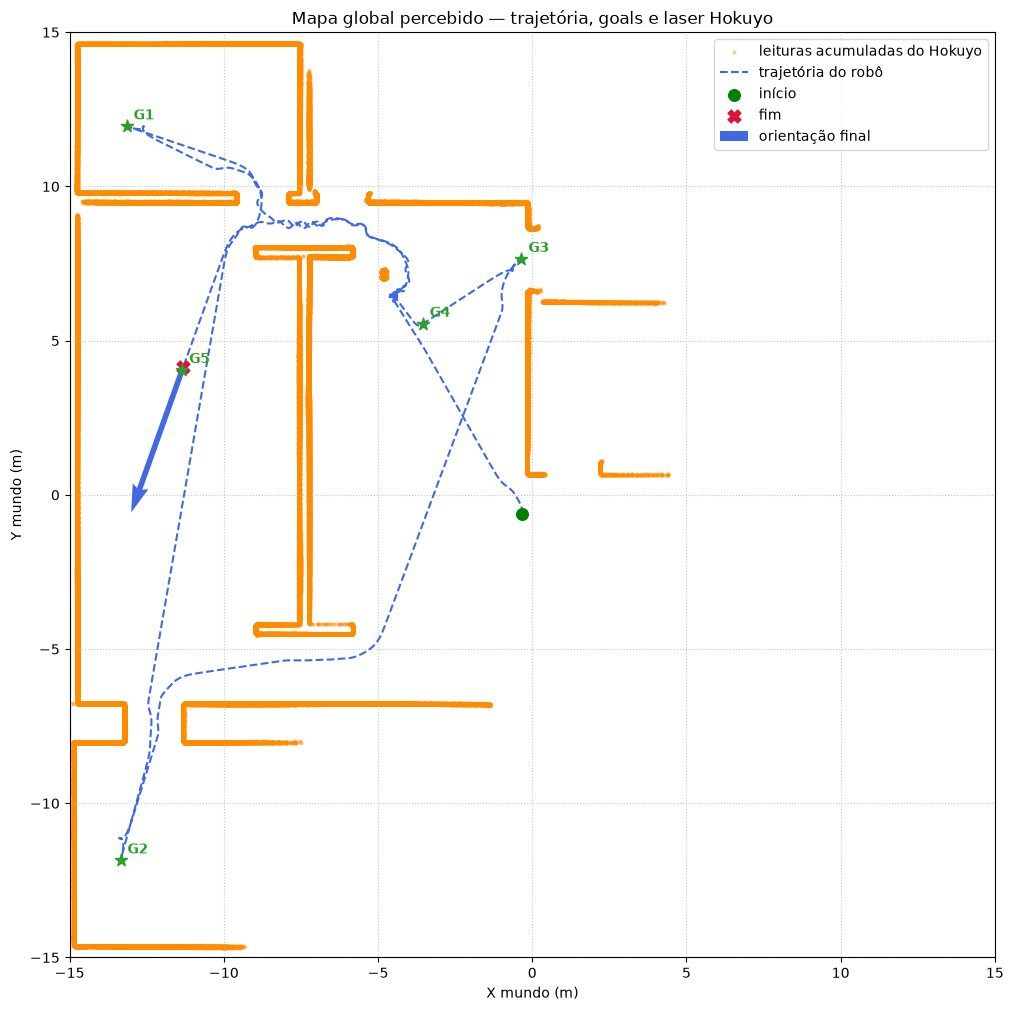

**Leitura global desta execução.** Foram acumulados **378146** pontos válidos do Hokuyo. Pontos fora do alcance útil de 4,9 m, ausentes ou não finitos foram descartados; o mapa contém apenas as observações feitas ao longo da trajetória.

In [9]:
def plotar_mapa_global_percebido(
    pontos_laser: list[list[float]],
    trajetoria: list[tuple[float, float, float]],
):
    """Plota leituras acumuladas do Hokuyo no referencial global."""
    pontos = np.asarray(pontos_laser, dtype=float).reshape((-1, 2))
    poses = np.asarray(trajetoria, dtype=float).reshape((-1, 3))

    fig, ax = plt.subplots(figsize=(10, 10), constrained_layout=True)
    if len(pontos):
        ax.scatter(
            pontos[:, 0], pontos[:, 1], s=4, color='darkorange', alpha=0.35,
            rasterized=True, label='leituras acumuladas do Hokuyo',
        )
    ax.plot(poses[:, 0], poses[:, 1], '--', color='royalblue', linewidth=1.5, label='trajetória do robô')
    ax.scatter(*poses[0, :2], s=70, marker='o', color='green', zorder=4, label='início')
    ax.scatter(*poses[-1, :2], s=85, marker='X', color='crimson', zorder=4, label='fim')
    ax.quiver(
        poses[-1, 0], poses[-1, 1], np.cos(poses[-1, 2]), np.sin(poses[-1, 2]),
        color='royalblue', scale=6, width=0.006, zorder=5, label='orientação final',
    )
    for indice, (x, y) in enumerate(goals, start=1):
        cor = 'tab:green' if indice <= quantidade_alcancada else 'tab:red'
        ax.scatter(x, y, s=85, marker='*', color=cor, zorder=5)
        ax.annotate(f'G{indice}', (x, y), xytext=(5, 5), textcoords='offset points', color=cor, weight='bold')

    ax.set_xlim(EXTENT[0], EXTENT[1])
    ax.set_ylim(EXTENT[2], EXTENT[3])
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('X mundo (m)')
    ax.set_ylabel('Y mundo (m)')
    ax.set_title('Mapa global percebido — trajetória, goals e laser Hokuyo')
    ax.grid(True, linestyle=':', alpha=0.7)
    ax.legend(loc='upper right')
    return fig, ax, len(pontos)


fig_laser, ax_laser, quantidade_pontos_laser = plotar_mapa_global_percebido(
    pontos_laser_mundo, trajetoria
)
plt.show()
display(Markdown(
    f'**Leitura global desta execução.** Foram acumulados **{quantidade_pontos_laser}** pontos válidos do Hokuyo. '
    'Pontos fora do alcance útil de 4,9 m, ausentes ou não finitos foram descartados; '
    'o mapa contém apenas as observações feitas ao longo da trajetória.'
))


In [10]:
# Limpeza final: interrompe a simulacao e remove apenas os desenhos deste notebook.
simulacao_parada = False
if 'sim' in globals():
    try:
        sim.stopSimulation()
        simulacao_parada = True
    except Exception:
        pass  # A simulacao ja pode estar parada ou a conexao pode ter sido fechada.

desenhos_removidos = 0
for handle in globals().get('DESENHOS_CENA', []):
    try:
        sim.removeDrawingObject(handle)
        desenhos_removidos += 1
    except Exception:
        pass
DESENHOS_CENA = []

if 'cliente' in globals():
    try:
        cliente.setStepping(False)
    except Exception:
        pass

estado = 'solicitada a parada da simulacao' if simulacao_parada else 'simulacao ja parada ou indisponivel'
print(f'Limpeza concluida: {estado}; {desenhos_removidos} desenho(s) do notebook removido(s).')

Limpeza concluida: solicitada a parada da simulacao; 4 desenho(s) do notebook removido(s).
